# 05_Time_Series_Analysis — Trends Over Time (2000-2023)

In [1]:
import os
if 'notebooks' in os.getcwd():
    os.chdir('..')
print(f'Working directory: {os.getcwd()}')

Working directory: D:\Data analyst\Portfolio\project-1-refugee-integration


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_style('whitegrid')
print('✓ Libraries loaded')

✓ Libraries loaded


In [3]:
master = pd.read_parquet('data/processed/refugee_master_consolidated.parquet')
print(f'Time range: {master["Year"].min()} - {master["Year"].max()}')
print(f'Total records: {len(master)}')

Time range: 2000 - 2023
Total records: 29506


## 1. Global Integration Index Trend

In [4]:
global_trend = master.groupby('Year')['integration_index'].agg(['mean', 'std', 'min', 'max'])
print(global_trend.round(2))

       mean   std    min    max
Year                           
2000  44.68  6.14  32.25  62.84
2001  44.35  5.99  29.90  61.88
2002  48.97  6.66  29.48  59.52
2003  45.82  7.00  30.40  62.18
2004  46.94  5.71  35.12  61.36
2005  46.65  7.19  28.40  60.02
2006  48.55  5.18  37.60  60.23
2007  51.96  5.47  40.09  67.95
2008  49.16  5.90  34.89  66.02
2009  51.38  9.46  33.35  74.33
2010  50.52  6.11  41.23  67.56
2011  52.42  6.56  34.87  64.26
2012  52.62  5.62  41.86  64.38
2013  54.06  6.69  37.21  65.80
2014  57.33  5.82  42.68  71.29
2015  54.95  6.80  42.39  70.66
2016  58.95  6.66  42.85  69.30
2017  55.76  5.63  41.98  64.22
2018  60.19  8.77  45.14  75.64
2019  57.46  6.72  48.82  74.20
2020  59.67  4.63  49.69  69.10
2021  58.31  7.51  48.17  77.66
2022  64.31  6.77  50.24  79.50
2023  62.19  6.57  48.15  78.04


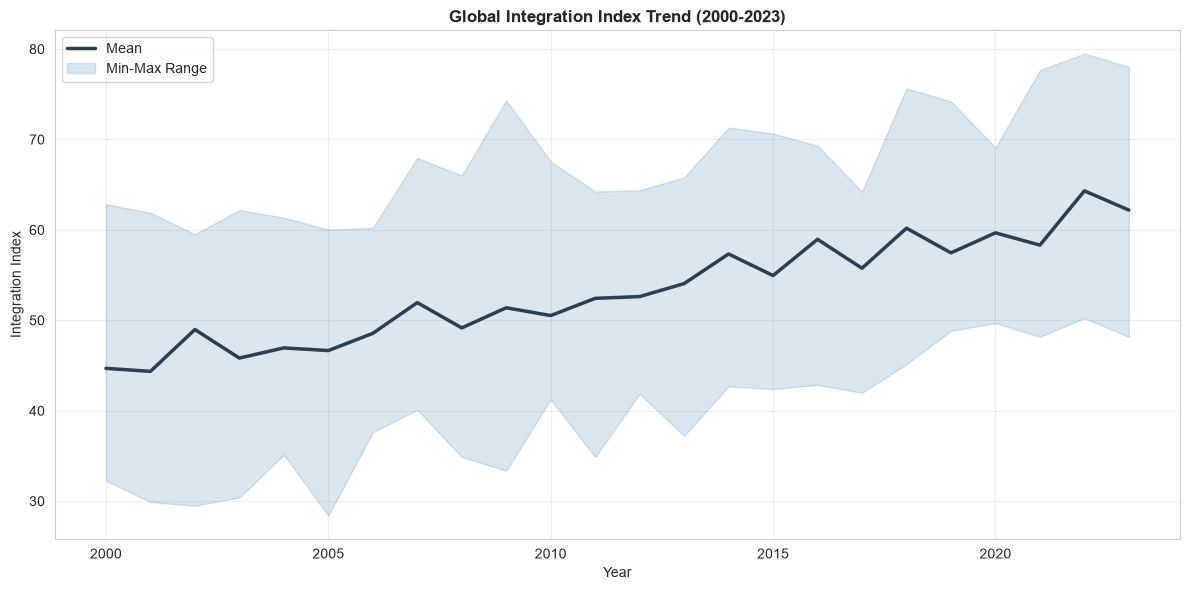

✓ Saved: 05_global_trend.png


In [5]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(global_trend.index, global_trend['mean'], linewidth=2.5, color='#2c3e50', label='Mean')
ax.fill_between(global_trend.index, global_trend['min'], global_trend['max'], alpha=0.2, color='steelblue', label='Min-Max Range')
ax.set_xlabel('Year')
ax.set_ylabel('Integration Index')
ax.set_title('Global Integration Index Trend (2000-2023)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('output/05_global_trend.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_global_trend.png')

## 2. Component Trends

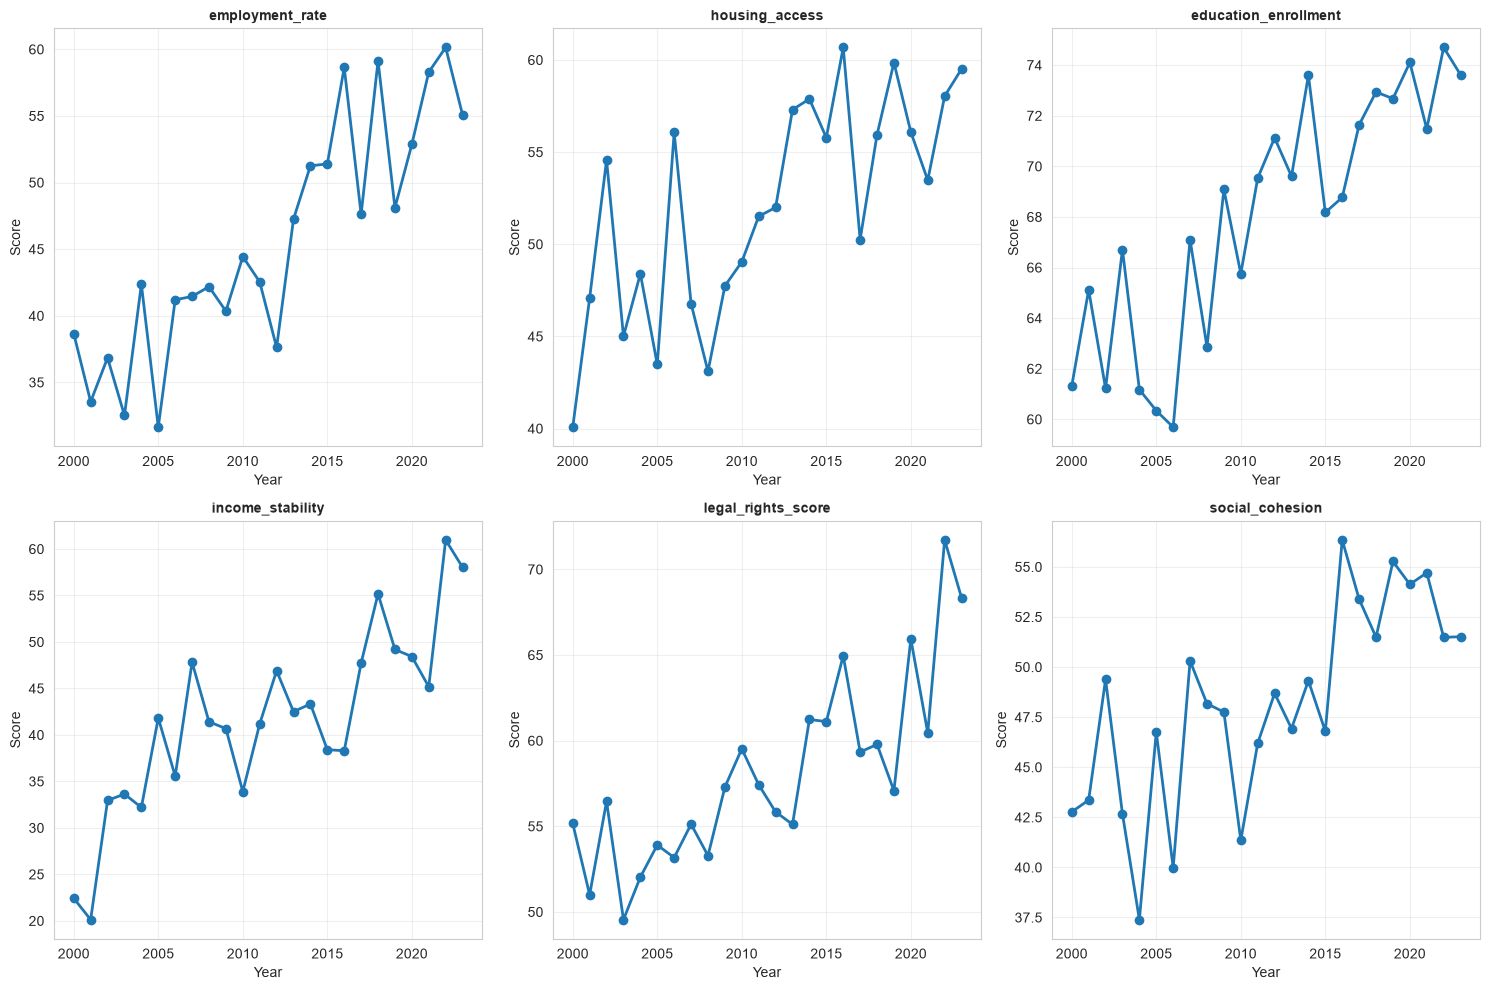

✓ Saved: 05_component_trends.png


In [6]:
components = ['employment_rate', 'housing_access', 'education_enrollment', 'income_stability', 'legal_rights_score', 'social_cohesion']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for i, comp in enumerate(components):
    trend = master.groupby('Year')[comp].mean()
    axes[i].plot(trend.index, trend.values, linewidth=2, marker='o')
    axes[i].set_title(f'{comp}', fontsize=10, fontweight='bold')
    axes[i].set_xlabel('Year')
    axes[i].set_ylabel('Score')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('output/05_component_trends.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_component_trends.png')

## 3. Regional Trend Comparison

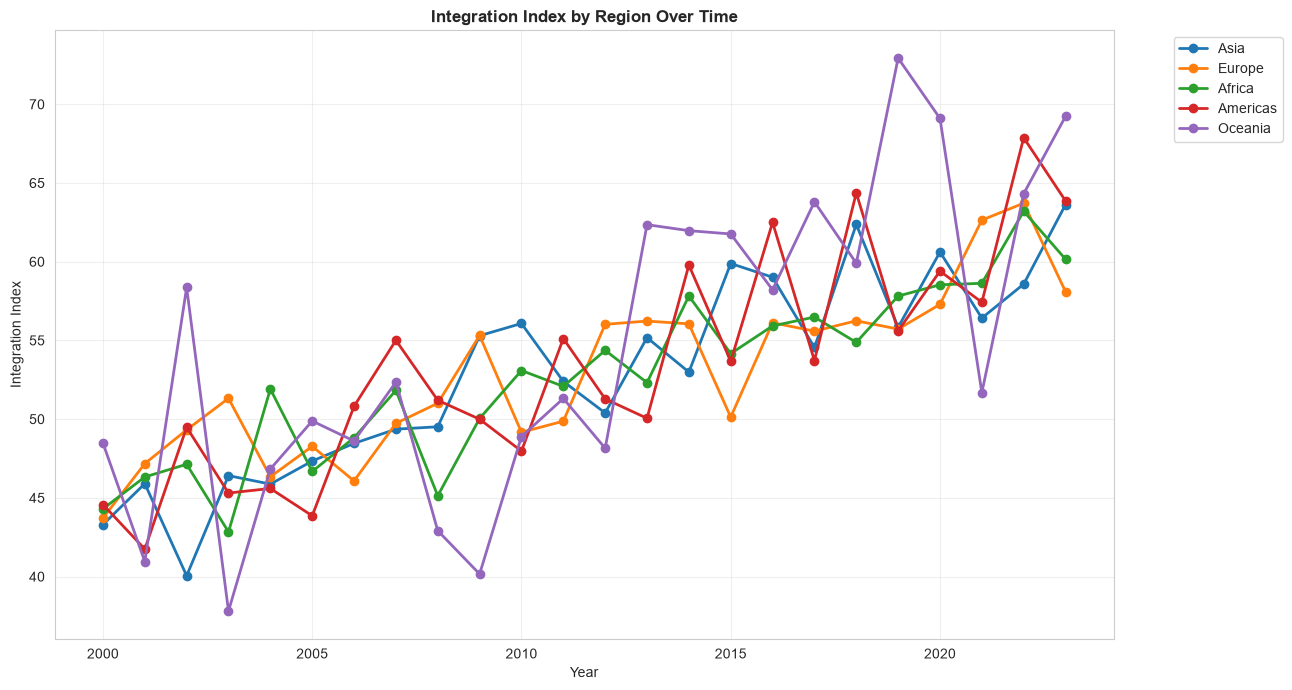

✓ Saved: 05_regional_trends.png


In [7]:
fig, ax = plt.subplots(figsize=(13, 7))

for region in master['region_un'].unique():
    if pd.notna(region):
        regional_data = master[master['region_un'] == region].groupby('Year')['integration_index'].mean()
        ax.plot(regional_data.index, regional_data.values, linewidth=2, marker='o', label=region)

ax.set_xlabel('Year')
ax.set_ylabel('Integration Index')
ax.set_title('Integration Index by Region Over Time', fontsize=12, fontweight='bold')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('output/05_regional_trends.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_regional_trends.png')

## 4. Refugee Volume Trends

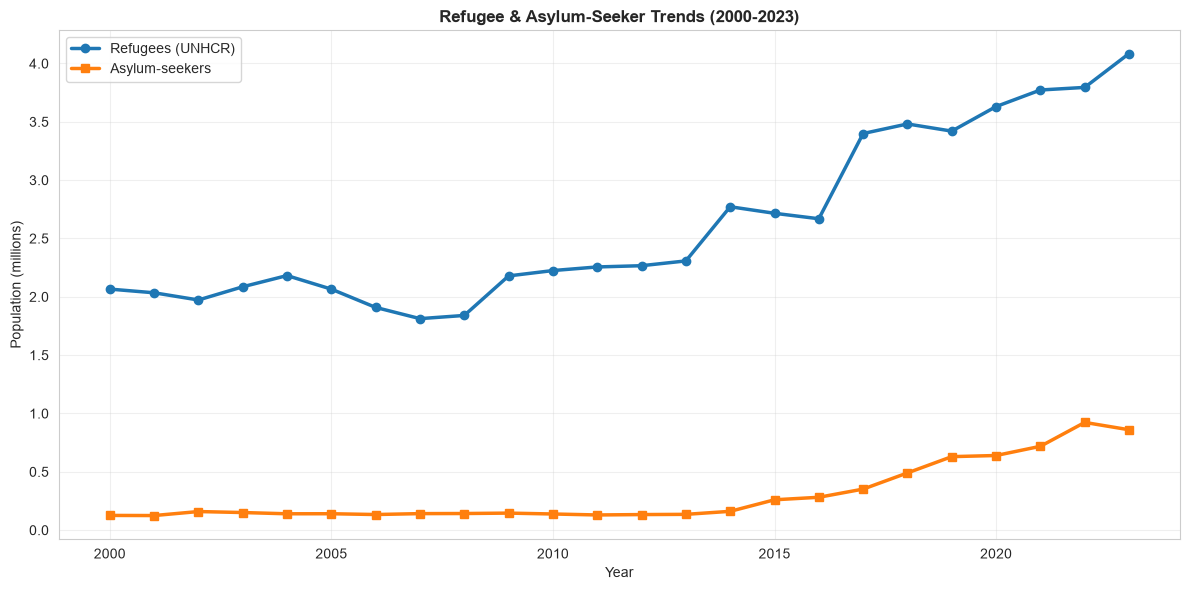

✓ Saved: 05_volume_trends.png


In [8]:
volume_trend = master.groupby('Year')[['Refugees under UNHCR\'s mandate', 'Asylum-seekers']].sum()

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(volume_trend.index, volume_trend['Refugees under UNHCR\'s mandate'] / 1e6, linewidth=2.5, marker='o', label='Refugees (UNHCR)')
ax.plot(volume_trend.index, volume_trend['Asylum-seekers'] / 1e6, linewidth=2.5, marker='s', label='Asylum-seekers')
ax.set_xlabel('Year')
ax.set_ylabel('Population (millions)')
ax.set_title('Refugee & Asylum-Seeker Trends (2000-2023)', fontsize=12, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('output/05_volume_trends.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_volume_trends.png')

## 5. Year-over-Year Change Analysis

In [9]:
annual_mean = master.groupby('Year')['integration_index'].mean()
yoy_change = annual_mean.pct_change() * 100

print('Year-over-Year % Change:')
print(yoy_change.round(2))

Year-over-Year % Change:
Year
2000      NaN
2001    -0.74
2002    10.42
2003    -6.44
2004     2.46
2005    -0.63
2006     4.08
2007     7.01
2008    -5.38
2009     4.53
2010    -1.68
2011     3.77
2012     0.37
2013     2.73
2014     6.06
2015    -4.17
2016     7.30
2017    -5.43
2018     7.95
2019    -4.54
2020     3.85
2021    -2.28
2022    10.29
2023    -3.30
Name: integration_index, dtype: float64


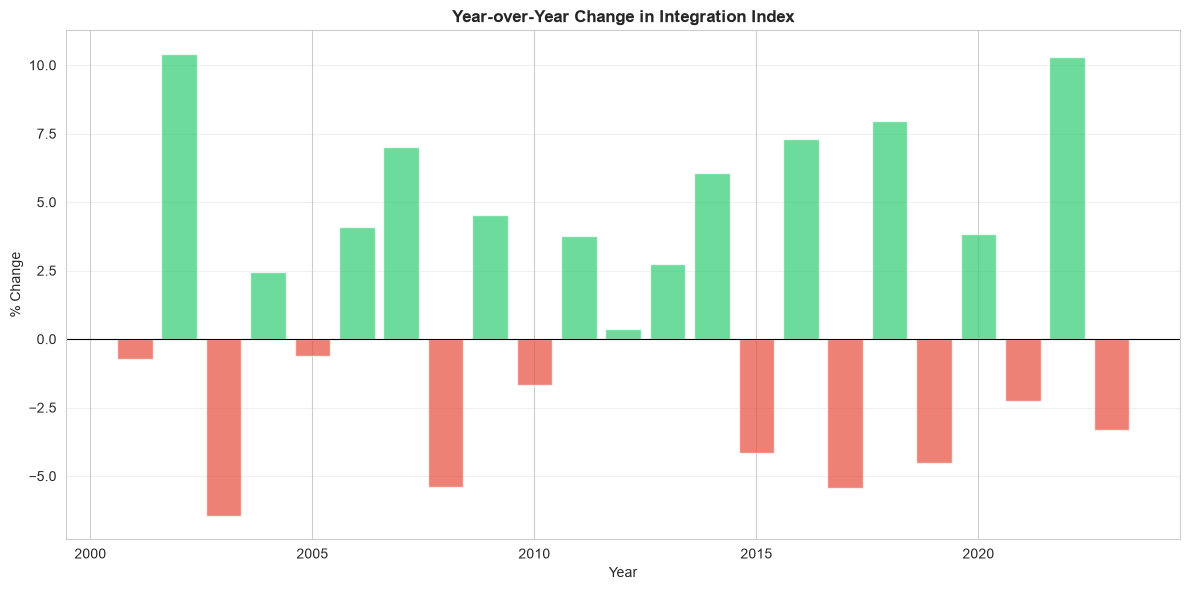

✓ Saved: 05_yoy_change.png


In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = ['#2ecc71' if x >= 0 else '#e74c3c' for x in yoy_change]
ax.bar(yoy_change.index, yoy_change.values, color=colors, alpha=0.7)
ax.axhline(y=0, color='black', linestyle='-', linewidth=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('% Change')
ax.set_title('Year-over-Year Change in Integration Index', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('output/05_yoy_change.png', dpi=300, bbox_inches='tight')
plt.show()
print('✓ Saved: 05_yoy_change.png')